<a href="https://colab.research.google.com/github/Lakshitha-Kavinda/cnn/blob/main/220316V_a02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Name:** Kavinda L.G.L.  
**Index number:** 220316V  
**GitHub:** https://github.com/Lakshitha-Kavinda/cnn.git

**AI tool acknowledgment:** I have used Claude to help with coding.

In [11]:
# from google.colab import drive
# drive.mount('/content/drive')
from google.colab import drive
drive.mount('/content/drive')

## Setup

In [9]:
import os, random, time
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed()

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', device)
if device.type == 'cuda':
    print(torch.cuda.get_device_name(0))

torch 2.11.0+cu130 | device: cuda
Tesla T4


### CIFAR-10: 45k train / 5k val, per-channel normalization with training statistics

In [10]:
DRIVE_DIR = '/content/drive/MyDrive/EN4554_A02'
DATA_ROOT = f'{DRIVE_DIR}/data'
os.makedirs(DATA_ROOT, exist_ok=True)
os.makedirs(f'{DRIVE_DIR}/results', exist_ok=True)

CLASSES = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']

full = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=True, download=True)   # skips download if already in Drive
X_all = torch.from_numpy(full.data).permute(0, 3, 1, 2).float() / 255.0
y_all = torch.tensor(full.targets)

# fixed split, saved to Drive so it never changes between sessions
perm_path = f'{DRIVE_DIR}/split_perm.pt'
if os.path.exists(perm_path):
    perm = torch.load(perm_path)
else:
    g = torch.Generator().manual_seed(SEED)
    perm = torch.randperm(len(X_all), generator=g)
    torch.save(perm, perm_path)
tr_idx, va_idx = perm[:45000], perm[45000:]

# per-channel statistics from the TRAINING split only
MEAN = X_all[tr_idx].mean(dim=(0, 2, 3), keepdim=True)
STD  = X_all[tr_idx].std(dim=(0, 2, 3), keepdim=True)
normalize = lambda x: (x - MEAN) / STD

X_train, y_train = normalize(X_all[tr_idx]).to(device), y_all[tr_idx].to(device)
X_val,   y_val   = normalize(X_all[va_idx]).to(device), y_all[va_idx].to(device)

def load_test():
    """Task 4 ONLY. Call once, on the final model."""
    t = torchvision.datasets.CIFAR10(root=DATA_ROOT, train=False, download=True)
    X = torch.from_numpy(t.data).permute(0, 3, 1, 2).float() / 255.0
    return normalize(X).to(device), torch.tensor(t.targets).to(device)

print('train', tuple(X_train.shape), '| val', tuple(X_val.shape))
print('mean', MEAN.flatten().tolist(), '\nstd ', STD.flatten().tolist())

100%|██████████| 170M/170M [43:46<00:00, 64.9kB/s]


train (45000, 3, 32, 32) | val (5000, 3, 32, 32)
mean [0.49165481328964233, 0.4823332130908966, 0.4466792047023773] 
std  [0.24708116054534912, 0.2435086965560913, 0.2615806758403778]


In [12]:
required = ['X_train', 'y_train', 'X_val', 'y_val', 'device', 'set_seed', 'SEED', 'DRIVE_DIR']
missing = [v for v in required if v not in globals()]
if missing:
    raise RuntimeError(f'Run the setup cells first (imports/seeds, GitHub, Google Drive data cell). Missing: {missing}')

os.makedirs(f'{DRIVE_DIR}/results', exist_ok=True)
os.makedirs(f'{DRIVE_DIR}/figures', exist_ok=True)

def savefig(name):
    # save to Drive (permanent) and, if the repo is cloned, to the repo's figures/ folder (for git)
    dirs = [f'{DRIVE_DIR}/figures']
    if 'REPO_DIR' in globals():
        dirs.append(f'{REPO_DIR}/figures')
    for d in dirs:
        os.makedirs(d, exist_ok=True)
        plt.savefig(f'{d}/{name}', dpi=150, bbox_inches='tight')

def result_path(name): return f'{DRIVE_DIR}/results/{name}.pt'
def result_exists(name): return os.path.exists(result_path(name))
def save_result(name, obj): torch.save(obj, result_path(name))
def load_result(name): return torch.load(result_path(name), weights_only=False)

print('device:', device, '| train', tuple(X_train.shape), '| val', tuple(X_val.shape))
print('Drive folder:', DRIVE_DIR)
print('Saved results so far:', sorted(os.listdir(f'{DRIVE_DIR}/results')))

device: cuda | train (45000, 3, 32, 32) | val (5000, 3, 32, 32)
Drive folder: /content/drive/MyDrive/EN4554_A02
Saved results so far: []


## Task 01

1) (a)


In [13]:
class Linear:
    def __init__(self, n_in, n_out, init='kaiming', dtype=torch.float32, device='cpu'):
        if init == 'kaiming':   std = (2.0 / n_in) ** 0.5            # He init (for ReLU)
        elif init == 'xavier':  std = (2.0 / (n_in + n_out)) ** 0.5  # Glorot init
        else: raise ValueError(init)
        self.W = torch.randn(n_in, n_out, dtype=dtype, device=device) * std
        self.b = torch.zeros(n_out, dtype=dtype, device=device)
        self.dW = torch.zeros_like(self.W)
        self.db = torch.zeros_like(self.b)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW = self.x.T @ dout          # (in, N) @ (N, out)
        self.db = dout.sum(dim=0)
        return dout @ self.W.T             # gradient w.r.t. the input

    def step(self, lr):                    # plain SGD update
        self.W -= lr * self.dW
        self.b -= lr * self.db


class ReLU:
    def forward(self, x):
        self.mask = (x > 0)
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask


class Sigmoid:
    def forward(self, x):
        self.y = 1.0 / (1.0 + torch.exp(-x))
        return self.y

    def backward(self, dout):
        return dout * self.y * (1.0 - self.y)


class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        z = logits - logits.max(dim=1, keepdim=True).values            # numerical stability
        logp = z - torch.logsumexp(z, dim=1, keepdim=True)
        self.p = logp.exp()
        self.y = y
        return -logp[torch.arange(len(y), device=y.device), y].mean()

    def backward(self):
        g = self.p.clone()
        g[torch.arange(len(self.y), device=self.y.device), self.y] -= 1.0
        return g / len(self.y)


class MLP:
    def __init__(self, sizes, act='relu', init='kaiming', dtype=torch.float32, device='cpu'):
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], init, dtype, device))
            if i < len(sizes) - 2:                                      # no activation after the last layer
                self.layers.append(ReLU() if act == 'relu' else Sigmoid())
        self.loss_fn = SoftmaxCrossEntropy()

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def loss(self, x, y):
        return self.loss_fn.forward(self.forward(x), y)

    def backward(self):
        g = self.loss_fn.backward()
        for layer in reversed(self.layers):
            g = layer.backward(g)

    def linears(self):
        return [l for l in self.layers if isinstance(l, Linear)]

    def step(self, lr):
        for l in self.linears():
            l.step(lr)

# quick shape / sanity test
_net = MLP([3072, 512, 256, 10], device=device)
_l = _net.loss(X_train[:64].flatten(1), y_train[:64]); _net.backward()
print('loss at init:', round(_l.item(), 3), '(about ln(10) = 2.303 for small logits)')
print('grad shapes :', [tuple(l.dW.shape) for l in _net.linears()])

loss at init: 2.975 (about ln(10) = 2.303 for small logits)
grad shapes : [(3072, 512), (512, 256), (256, 10)]


1) (b)

In [15]:
def rel_err(a, b):
    return ((a - b).norm() / (a.norm() + b.norm() + 1e-12)).item()

def ref_forward(ps, x, act):
    # same network written with ordinary autograd ops
    h, n = x, len(ps) // 2
    for i in range(n):
        h = h @ ps[2 * i] + ps[2 * i + 1]
        if i < n - 1:
            h = F.relu(h) if act == 'relu' else torch.sigmoid(h)
    return h

def grad_check(act, h=1e-5, n_probe=10, seed=0):
    torch.manual_seed(seed)
    n_in, hid, n_cls, B = 20, 16, 10, 8
    net = MLP([n_in, hid, hid, n_cls], act=act, dtype=torch.float64)       # cpu, float64
    for l in net.linears():
        l.b = torch.randn_like(l.b) * 0.1                                  # non-zero biases, so db is tested properly
    xb = torch.randn(B, n_in, dtype=torch.float64)
    yb = torch.randint(0, n_cls, (B,))

    # manual
    loss_manual = net.loss(xb, yb); net.backward()
    manual = []
    for l in net.linears(): manual += [l.dW.clone(), l.db.clone()]
    names = [f'{k}{i + 1}' for i in range(len(net.linears())) for k in ('W', 'b')]

    # autograd
    ps = []
    for l in net.linears(): ps += [l.W.clone().requires_grad_(True), l.b.clone().requires_grad_(True)]
    loss_ag = F.cross_entropy(ref_forward(ps, xb, act), yb)
    loss_ag.backward()
    auto = [p.grad for p in ps]

    # centred finite differences (perturb the network's own parameters in place)
    params = []
    for l in net.linears(): params += [l.W, l.b]
    g = torch.Generator().manual_seed(seed)
    rows = []
    for name, p, gm, ga in zip(names, params, manual, auto):
        flat = p.view(-1)
        idx = torch.randperm(flat.numel(), generator=g)[:n_probe]
        worst = 0.0
        for i in idx.tolist():
            orig = flat[i].item()
            flat[i] = orig + h; lp = net.loss(xb, yb).item()
            flat[i] = orig - h; lm = net.loss(xb, yb).item()
            flat[i] = orig
            num, ana = (lp - lm) / (2 * h), gm.view(-1)[i].item()
            worst = max(worst, abs(num - ana) / (abs(num) + abs(ana) + 1e-12))
        rows.append((name, rel_err(gm, ga), torch.allclose(gm, ga, rtol=1e-7, atol=1e-10), worst))
    return abs(loss_manual.item() - loss_ag.item()), rows

check_results = {}
for act in ['relu']:
    dloss, rows = grad_check(act)
    check_results[act] = {'loss_diff': dloss, 'rows': rows}
    print(f'\n=== {act.upper()} MLP  |  |loss_manual - loss_autograd| = {dloss:.2e} ===')
    print(f'{"param":6s} {"rel.err vs autograd":>20s} {"allclose":>9s} {"max rel.err vs finite-diff":>28s}')
    for name, e_ag, ok, e_fd in rows:
        print(f'{name:6s} {e_ag:20.2e} {str(ok):>9s} {e_fd:28.2e}')
save_result('task1b_gradcheck', check_results)     # kept on Drive for the report


=== RELU MLP  |  |loss_manual - loss_autograd| = 0.00e+00 ===
param   rel.err vs autograd  allclose   max rel.err vs finite-diff
W1                 5.26e-17      True                     1.69e-09
b1                 4.22e-17      True                     8.73e-10
W2                 3.39e-17      True                     1.62e-08
b2                 9.49e-17      True                     2.63e-10
W3                 3.17e-17      True                     1.81e-10
b3                 5.21e-17      True                     4.58e-10


1) (c)

In [16]:
def mb_iter(X, y, bs, seed):
    g = torch.Generator().manual_seed(seed)
    idx = torch.randperm(len(X), generator=g).to(X.device)
    for i in range(0, len(X), bs):
        j = idx[i:i + bs]
        yield X[j], y[j]

def evaluate(net, X, y, bs=1000):
    tot, correct = 0.0, 0
    for i in range(0, len(X), bs):
        xb, yb = X[i:i + bs], y[i:i + bs]
        logits = net.forward(xb)
        tot += net.loss_fn.forward(logits, yb).item() * len(xb)
        correct += (logits.argmax(1) == yb).sum().item()
    return tot / len(X), correct / len(X)

def train_mlp(sizes, lr=0.05, epochs=20, bs=128, seed=42):
    set_seed(seed)
    net = MLP(sizes, act='relu', init='kaiming', device=device)
    Xtr, Xva = X_train.flatten(1), X_val.flatten(1)
    hist = {'iter_loss': [], 'train_loss': [], 'val_loss': [], 'val_acc': []}
    t0 = time.time()
    for ep in range(epochs):
        batch_losses = []
        for xb, yb in mb_iter(Xtr, y_train, bs, seed * 1000 + ep):
            loss = net.loss(xb, yb)
            net.backward()
            net.step(lr)
            batch_losses.append(loss.item())
        hist['iter_loss'] += batch_losses
        hist['train_loss'].append(float(np.mean(batch_losses)))
        vl, va = evaluate(net, Xva, y_val)
        hist['val_loss'].append(vl); hist['val_acc'].append(va)
        print(f'epoch {ep + 1:2d} | train loss {hist["train_loss"][-1]:.4f} | val loss {vl:.4f} | val acc {va:.4f}')
    print(f'done in {time.time() - t0:.0f}s')
    return net, hist

SIZES_C = [3072, 512, 256, 10]
RETRAIN = False        # set True to force retraining even if a saved result exists on Drive

if result_exists('task1c') and not RETRAIN:
    ck = load_result('task1c')
    hist_c = ck['hist']
    net_c = MLP(SIZES_C, act='relu', init='kaiming', device=device)
    for l, (W, b) in zip(net_c.linears(), ck['weights']):
        l.W, l.b = W.to(device), b.to(device)
    print('Loaded saved Task 1(c) result from Drive (no retraining). Set RETRAIN = True to train again.')
    print('Sanity check, val acc of the loaded network: %.4f' % evaluate(net_c, X_val.flatten(1), y_val)[1])
else:
    net_c, hist_c = train_mlp(SIZES_C)
    save_result('task1c', {'hist': hist_c, 'weights': [(l.W.cpu(), l.b.cpu()) for l in net_c.linears()]})
    print('Saved Task 1(c) result to Drive.')

epoch  1 | train loss 1.6931 | val loss 1.5394 | val acc 0.4652
epoch  2 | train loss 1.4140 | val loss 1.5013 | val acc 0.4814
epoch  3 | train loss 1.2873 | val loss 1.4620 | val acc 0.4848
epoch  4 | train loss 1.1878 | val loss 1.4500 | val acc 0.4978
epoch  5 | train loss 1.1014 | val loss 1.4332 | val acc 0.5044
epoch  6 | train loss 1.0166 | val loss 1.4668 | val acc 0.5026
epoch  7 | train loss 0.9458 | val loss 1.5447 | val acc 0.4830
epoch  8 | train loss 0.8712 | val loss 1.5685 | val acc 0.4980
epoch  9 | train loss 0.8050 | val loss 1.5595 | val acc 0.5064
epoch 10 | train loss 0.7417 | val loss 1.5862 | val acc 0.5050
epoch 11 | train loss 0.6792 | val loss 1.6580 | val acc 0.4968
epoch 12 | train loss 0.6164 | val loss 1.7038 | val acc 0.5036
epoch 13 | train loss 0.5618 | val loss 1.7730 | val acc 0.4966
epoch 14 | train loss 0.5125 | val loss 1.7848 | val acc 0.5108
epoch 15 | train loss 0.4658 | val loss 1.8591 | val acc 0.5142
epoch 16 | train loss 0.4149 | val loss 

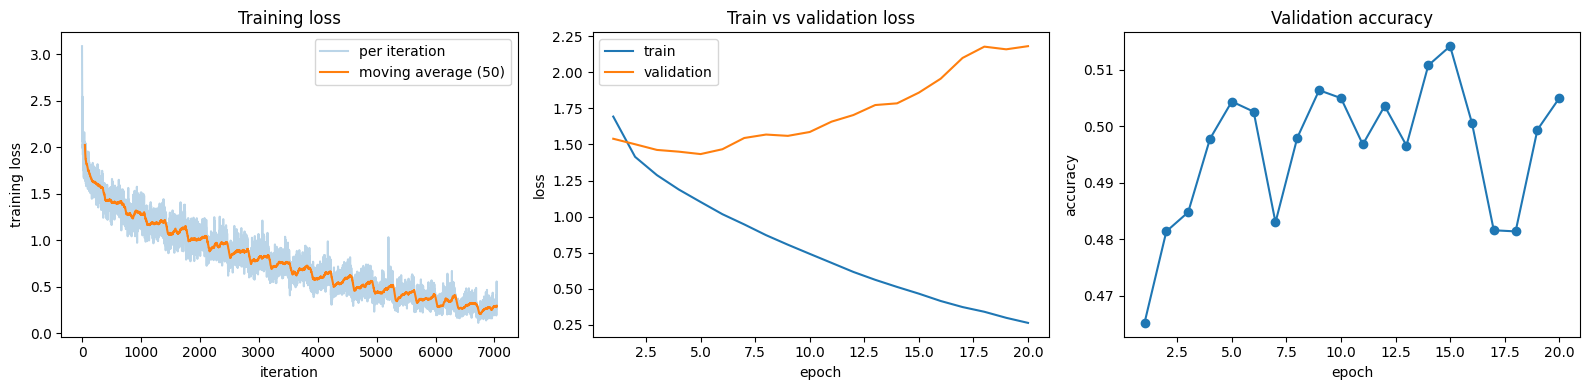

Final validation accuracy: 50.50%   (best: 51.42% at epoch 15)
Final train loss 0.263  |  final val loss 2.181


In [17]:
it = np.array(hist_c['iter_loss'])
k = 50
smooth = np.convolve(it, np.ones(k) / k, mode='valid')
ep_axis = np.arange(1, len(hist_c['train_loss']) + 1)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(it, alpha=0.3, label='per iteration')
ax[0].plot(np.arange(k - 1, len(it)), smooth, label=f'moving average ({k})')
ax[0].set_xlabel('iteration'); ax[0].set_ylabel('training loss'); ax[0].set_title('Training loss'); ax[0].legend()
ax[1].plot(ep_axis, hist_c['train_loss'], label='train'); ax[1].plot(ep_axis, hist_c['val_loss'], label='validation')
ax[1].set_xlabel('epoch'); ax[1].set_ylabel('loss'); ax[1].set_title('Train vs validation loss'); ax[1].legend()
ax[2].plot(ep_axis, hist_c['val_acc'], marker='o')
ax[2].set_xlabel('epoch'); ax[2].set_ylabel('accuracy'); ax[2].set_title('Validation accuracy')
plt.tight_layout(); savefig('task1c_training.png'); plt.show()

final_acc = hist_c['val_acc'][-1]
print(f'Final validation accuracy: {final_acc * 100:.2f}%   (best: {max(hist_c["val_acc"]) * 100:.2f}% at epoch {int(np.argmax(hist_c["val_acc"])) + 1})')
print(f'Final train loss {hist_c["train_loss"][-1]:.3f}  |  final val loss {hist_c["val_loss"][-1]:.3f}')

1) (d)

Sigmoid + Xavier         init loss  2.509 | layer1 1.39e-05  layer5 1.31e-03  layer10 1.40e+00 | layer1/layer10 = 9.94e-06
ReLU + Kaiming           init loss  2.708 | layer1 3.00e+00  layer5 1.75e+00  layer10 3.07e+00 | layer1/layer10 = 9.78e-01
ReLU + Xavier (extra)    init loss  2.304 | layer1 1.40e-01  layer5 5.79e-02  layer10 3.61e-02 | layer1/layer10 = 3.87e+00


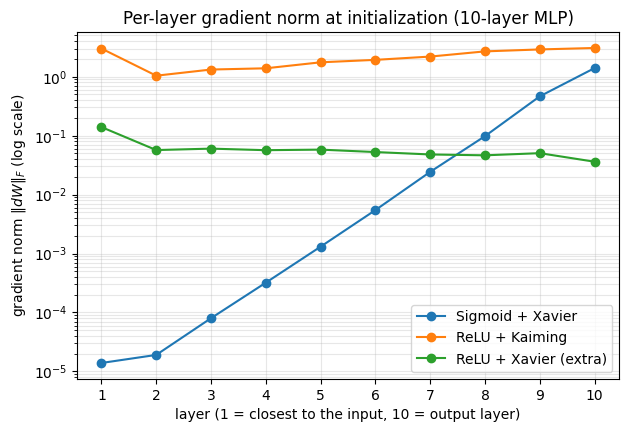

In [18]:
def layer_grad_norms(act, init, depth=10, width=256, bs=512, seed=42):
    set_seed(seed)
    sizes = [3072] + [width] * (depth - 1) + [10]          # depth Linear layers in total
    net = MLP(sizes, act=act, init=init, device=device)
    xb, yb = X_train[:bs].flatten(1), y_train[:bs]
    loss = net.loss(xb, yb); net.backward()
    return [l.dW.norm().item() for l in net.linears()], loss.item()

configs = [('sigmoid', 'xavier', 'Sigmoid + Xavier'),
           ('relu',    'kaiming', 'ReLU + Kaiming'),
           ('relu',    'xavier',  'ReLU + Xavier (extra)')]
norms = {}
for act, init, label in configs:
    norms[label], l0 = layer_grad_norms(act, init)
    n = norms[label]
    print(f'{label:24s} init loss {l0:6.3f} | layer1 {n[0]:.2e}  layer5 {n[4]:.2e}  layer10 {n[-1]:.2e} | layer1/layer10 = {n[0] / n[-1]:.2e}')

save_result('task1d_gradnorms', norms)             # kept on Drive for the report

layers = np.arange(1, 11)
plt.figure(figsize=(7, 4.5))
for label, n in norms.items():
    plt.semilogy(layers, n, marker='o', label=label)
plt.xlabel('layer (1 = closest to the input, 10 = output layer)')
plt.ylabel(r'gradient norm $\|dW\|_F$ (log scale)')
plt.title('Per-layer gradient norm at initialization (10-layer MLP)')
plt.xticks(layers); plt.grid(alpha=0.3, which='both'); plt.legend()
savefig('task1d_grad_norms.png'); plt.show()

In [19]:
print('--- Task 1 summary ---')
dl, rows = grad_check('relu')
print('Gradient check (ReLU): max rel.err vs autograd = %.1e | max rel.err vs finite diff = %.1e | all allclose = %s'
      % (max(r[1] for r in rows), max(r[3] for r in rows), all(r[2] for r in rows)))
print('MLP 3072-512-256-10, SGD lr=0.05, 20 epochs: val acc = %.2f%%' % (hist_c['val_acc'][-1] * 100))
n_s, n_r = norms['Sigmoid + Xavier'], norms['ReLU + Kaiming']
print('Grad-norm ratio layer1/layer10: sigmoid = %.1e, relu = %.1e' % (n_s[0] / n_s[-1], n_r[0] / n_r[-1]))

--- Task 1 summary ---
Gradient check (ReLU): max rel.err vs autograd = 9.5e-17 | max rel.err vs finite diff = 1.6e-08 | all allclose = True
MLP 3072-512-256-10, SGD lr=0.05, 20 epochs: val acc = 50.50%
Grad-norm ratio layer1/layer10: sigmoid = 9.9e-06, relu = 9.8e-01
